# Subgroup performance: MSP vs our model, all diseases

For every disease and every patient subgroup (sex, age, race, ...) we compute the AUROC of
predicting **whether C0 is correct**, for two scores:

* **MSP**: threshold-MSP from C0's probability (the baseline)
* **Ours**: the final K=10 ensemble (`MLP_I+C+D` + `dual_sal` CNN)

Demographics come from **CheXpert Plus** (age, sex, race, ethnicity, BMI, insurance, AP/PA) and
**Support Devices** comes from the CheXpert labels in `C2_dataset.csv`.

Note: AUROC here is computed on all 5 folds pooled together, not as the mean over folds, so the
overall numbers differ slightly from `C2_evaluation.ipynb`.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

sys.path.insert(0, os.path.abspath("code"))
from c2_msp import msp_score
from thesis_style import ENS, GREY   # thesis colours: ensemble purple, MSP grey

## Settings

In [2]:
DISEASES = ["effusion", "atelectasis", "cardiomegaly", "consolidation", "edema"]
K        = 10
MIN_N    = 100          # skip subgroups with fewer images than this

RESULTS = "/work3/s251710/thesis_results"
DATA    = "/work3/s251710/thesis_data"

CXP_PLUS_FILE = f"{DATA}/CheXpertPlus/df_chexpert_plus_240401.csv.xls"
C2_DATASET    = "C2_dataset.csv"

## 1. Load the metadata (once, shared by all diseases)

CheXpert Plus paths look like `train/patient.../view1_frontal.jpg`, and ours look like
`CheXpert-v1.0-small/train/patient.../view1_frontal.jpg`, so we add the prefix.

In [3]:
cxp_plus = pd.read_csv(CXP_PLUS_FILE, usecols=["path_to_image", "age", "sex", "race", "ethnicity",
                                                "recent_bmi", "insurance_type", "ap_pa"])
cxp_plus["path"] = "CheXpert-v1.0-small/" + cxp_plus["path_to_image"]
cxp_plus = cxp_plus.drop(columns="path_to_image")

devices = pd.read_csv(C2_DATASET, usecols=["Path", "Support Devices"])
devices = devices.rename(columns={"Path": "path", "Support Devices": "support_devices"})
devices = devices.drop_duplicates("path")

meta = devices.merge(cxp_plus, on="path", how="left")
print("images:", len(meta), "| without CheXpert Plus metadata:", meta["sex"].isna().sum())

images: 95835 | without CheXpert Plus metadata: 76


## 2. Define the subgroups

* Age and BMI are binned.
* "Unknown" and "Patient Refused" are merged into one group.
* Support Devices: 1 = Present, 0 = Absent, -1 or missing = Unknown.

In [4]:
meta["age_group"] = pd.cut(meta["age"], bins=[0, 40, 60, 80, 200], labels=["<40", "40-60", "60-80", "80+"])

meta["bmi_group"] = pd.cut(meta["recent_bmi"], bins=[0, 18.5, 25, 30, 200],
                           labels=["Underweight", "Normal", "Overweight", "Obese"])

meta["race"]      = meta["race"].replace({"Unknown": "Unknown/Refused", "Patient Refused": "Unknown/Refused"})
meta["ethnicity"] = meta["ethnicity"].replace({"Unknown": "Unknown/Refused", "Patient Refused": "Unknown/Refused"})

meta["support_devices"] = meta["support_devices"].map({1: "Present", 0: "Absent", -1: "Unknown"}).fillna("Unknown")

# Subgroup axes: {plot title: column name}
AXES = {
    "Sex":             "sex",
    "Age":             "age_group",
    "Race":            "race",
    "Ethnicity":       "ethnicity",
    "BMI":             "bmi_group",
    "Insurance":       "insurance_type",
    "View (AP/PA)":    "ap_pa",
    "Support devices": "support_devices",
}

meta = meta[["path"] + list(AXES.values())]
meta.head()

,path,sex,age_group,race,ethnicity,bmi_group,insurance_type,ap_pa,support_devices
0,CheXpert-v1.0-small/train/patient00001/study1/...,Female,60-80,Other,Non-Hispanic/Non-Latino,Obese,Medicare,AP,Present
1,CheXpert-v1.0-small/train/patient00002/study2/...,Female,80+,White,Non-Hispanic/Non-Latino,Normal,Unknown,AP,Absent
2,CheXpert-v1.0-small/train/patient00002/study1/...,Female,80+,White,Non-Hispanic/Non-Latino,Normal,Unknown,AP,Absent
3,CheXpert-v1.0-small/train/patient00004/study1/...,Female,<40,Black,Non-Hispanic/Non-Latino,Normal,Medicaid,PA,Absent
4,CheXpert-v1.0-small/train/patient00005/study1/...,Male,<40,White,Non-Hispanic/Non-Latino,Normal,Private Insurance,PA,Present


## 3. Load the predictions of one disease

`oof_predictions.csv` has one row per image with `correct` (1 = C0 was right) and the ensemble
scores `ens_mean`, `ens_rank`, `ens_lr`. We use whichever combiner had the best AUROC in
`ensemble_summary.csv`.

MSP needs C0's probability, which is stored in the attribute model's fold files, and C0's
threshold.

In [5]:
def load_predictions(disease):
    run_dir = f"{RESULTS}/C2_final_results/{disease}/knn_correct_cf/cf_{K}"

    # Our model
    preds = pd.read_csv(f"{run_dir}/ensemble/oof_predictions.csv")
    summary = pd.read_csv(f"{run_dir}/ensemble/ensemble_summary.csv")
    summary = summary[summary["kind"] == "ensemble"]
    best_method = summary.sort_values("auc_mean", ascending=False)["method"].iloc[0]
    preds["ours"] = preds[f"ens_{best_method}"]

    # MSP
    c0_probs = []
    for fold in range(5):
        f = pd.read_csv(f"{run_dir}/attributes/fold_{fold}_predictions.csv", usecols=["path", f"{disease}_prob"])
        c0_probs.append(f)
    c0_probs = pd.concat(c0_probs, ignore_index=True)
    preds = preds.merge(c0_probs, on="path", how="left")

    threshold = float(open(f"{RESULTS}/C0_final/multilabel_ignore/{disease}/threshold.txt").read())
    preds["msp"] = msp_score(preds[f"{disease}_prob"].values, threshold, "threshold")

    print(f"{disease:14s} rows: {len(preds):6d} | combiner: {best_method} | C0 threshold: {threshold:.3f}")
    return preds[["path", "correct", "msp", "ours"]]


load_predictions("effusion").head()

effusion       rows:  90934 | combiner: lr | C0 threshold: 0.393


,path,correct,msp,ours
0,CheXpert-v1.0-small/train/patient00002/study1/...,0,0.838125,0.489009
1,CheXpert-v1.0-small/train/patient00005/study1/...,1,0.977517,0.866227
2,CheXpert-v1.0-small/train/patient00005/study2/...,0,0.415597,0.211916
3,CheXpert-v1.0-small/train/patient00005/study2/...,0,0.615968,0.228562
4,CheXpert-v1.0-small/train/patient00014/study1/...,1,0.994969,0.906408


## 4. AUROC per subgroup

For every group: number of images, number of C0 errors, C0 accuracy, and the AUROC of MSP and
of our model for predicting `correct`. `gain` = ours - MSP.

Groups with fewer than `MIN_N` images, or where C0 is always right (or always wrong), are
skipped because AUROC is not defined or too noisy there.

In [6]:
def subgroup_table(df, col):
    rows = []
    for group, sub in df.groupby(col, observed=True):
        n = len(sub)
        if n < MIN_N or sub["correct"].nunique() < 2:
            continue
        auc_msp  = roc_auc_score(sub["correct"], sub["msp"])
        auc_ours = roc_auc_score(sub["correct"], sub["ours"])
        rows.append({
            "group":    group,
            "n":        n,
            "n_errors": int((sub["correct"] == 0).sum()),
            "C0_acc":   sub["correct"].mean(),
            "auc_msp":  auc_msp,
            "auc_ours": auc_ours,
            "gain":     auc_ours - auc_msp,
        })
    return pd.DataFrame(rows)

## 5. Run every disease

`results` is one long table: one row per (disease, axis, group). `overall` has one row per disease.

In [7]:
results = []
overall = []

for disease in DISEASES:
    df = load_predictions(disease).merge(meta, on="path", how="left")

    overall.append({
        "disease":  disease,
        "n":        len(df),
        "auc_msp":  roc_auc_score(df["correct"], df["msp"]),
        "auc_ours": roc_auc_score(df["correct"], df["ours"]),
    })

    for axis, col in AXES.items():
        table = subgroup_table(df, col)
        table.insert(0, "axis", axis)
        table.insert(0, "disease", disease)
        results.append(table)

results = pd.concat(results, ignore_index=True)
overall = pd.DataFrame(overall)
overall["gain"] = overall["auc_ours"] - overall["auc_msp"]
overall.round(4)

effusion       rows:  90934 | combiner: lr | C0 threshold: 0.393


atelectasis    rows:  80938 | combiner: lr | C0 threshold: 0.189


cardiomegaly   rows:  92507 | combiner: lr | C0 threshold: 0.160


consolidation  rows:  83688 | combiner: rank | C0 threshold: 0.067


edema          rows:  89852 | combiner: lr | C0 threshold: 0.285


,disease,n,auc_msp,auc_ours,gain
0,effusion,90934,0.7817,0.7871,0.0054
1,atelectasis,80938,0.8632,0.8622,-0.0011
2,cardiomegaly,92507,0.9169,0.9194,0.0025
3,consolidation,83688,0.9463,0.9455,-0.0007
4,edema,89852,0.8303,0.8370,0.0066


In [8]:
# The full table, one disease at a time
for disease in DISEASES:
    print(f"\n=================== {disease} ===================")
    print(results[results["disease"] == disease].drop(columns="disease").round(4).to_string(index=False))


=================== effusion ===================
           axis                   group     n  n_errors  C0_acc  auc_msp  auc_ours   gain
            Sex                  Female 37663      7616  0.7978   0.7850    0.7897 0.0047
            Sex                    Male 53083     11037  0.7921   0.7795    0.7854 0.0059
            Sex                 Unknown   114        24  0.7895   0.7963    0.7968 0.0005
            Age                     <40 13610      2484  0.8175   0.8219    0.8273 0.0054
            Age                   40-60 29297      5750  0.8037   0.7857    0.7911 0.0054
            Age                   60-80 34987      7665  0.7809   0.7692    0.7739 0.0047
            Age                     80+ 12852      2754  0.7857   0.7594    0.7678 0.0085
           Race                   Asian  9494      1833  0.8069   0.7913    0.7943 0.0030
           Race                   Black  5007      1057  0.7889   0.7886    0.7964 0.0078
           Race         Native American   171     

## 6. Heatmap: gain over MSP, all diseases at once

Rows are subgroups and columns are diseases. Each cell is AUROC(ours) - AUROC(MSP) in that group.
Purple = we beat MSP, orange = MSP beats us. Empty cells are groups that were skipped (n < `MIN_N`).
The colour scale stops at ±0.01, so very small groups with big gains do not wash out the rest;
the printed number is always the real value.
The bottom row is the overall gain.

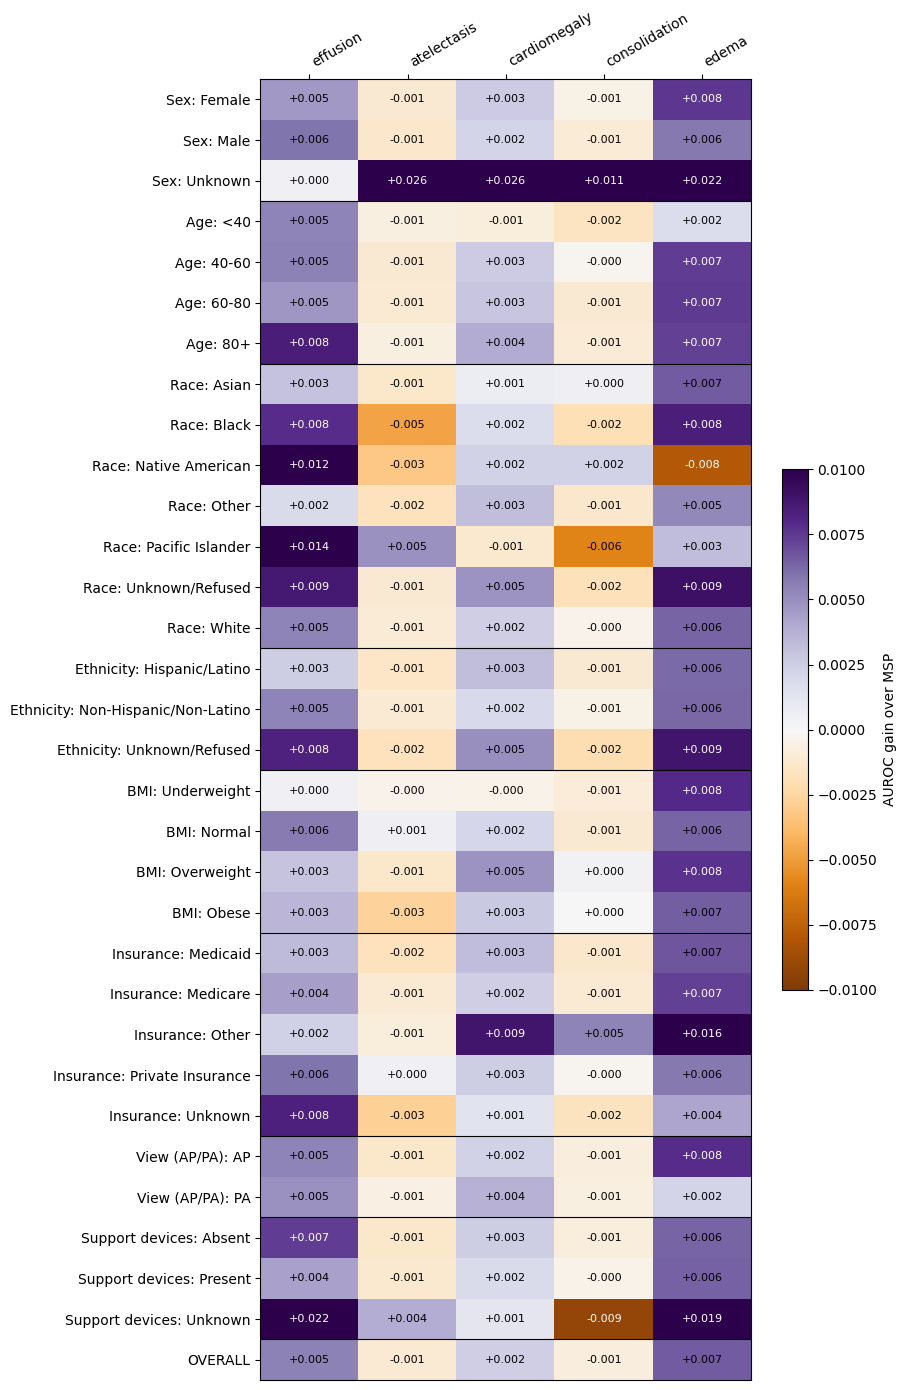

In [9]:
results["row"] = results["axis"] + ": " + results["group"].astype(str)
row_order = results.drop_duplicates("row")["row"].tolist()

heat = results.pivot(index="row", columns="disease", values="gain")
heat = heat.reindex(index=row_order, columns=DISEASES)
heat.loc["OVERALL"] = overall.set_index("disease")["gain"].reindex(DISEASES)

LIMIT = 0.01   # colour range is -0.01 .. +0.01; bigger gains (tiny groups) just saturate

fig, ax = plt.subplots(figsize=(9, 14))
im = ax.imshow(heat.values, cmap="PuOr", vmin=-LIMIT, vmax=LIMIT, aspect="auto")

for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        value = heat.values[i, j]
        if not np.isnan(value):
            text_color = "white" if abs(value) > 0.7 * LIMIT else "black"
            ax.text(j, i, f"{value:+.3f}", ha="center", va="center", fontsize=8, color=text_color)

ax.set_xticks(range(len(DISEASES)))
ax.set_xticklabels(DISEASES, rotation=30, ha="left")
ax.xaxis.tick_top()
ax.set_yticks(range(len(heat.index)))
ax.set_yticklabels(heat.index)

# Thin lines between the subgroup axes
axis_of_row = [r.split(":")[0] for r in heat.index]
for i in range(1, len(axis_of_row)):
    if axis_of_row[i] != axis_of_row[i - 1]:
        ax.axhline(i - 0.5, color="black", linewidth=0.8)

fig.colorbar(im, ax=ax, shrink=0.4, label="AUROC gain over MSP")
plt.tight_layout()
plt.show()

## 7. In how many subgroups do we beat MSP?

Per disease: the number of subgroups where the gain is positive, out of all subgroups shown.

In [10]:
wins = results.groupby("disease").agg(
    n_groups   = ("gain", "size"),
    n_wins     = ("gain", lambda g: int((g > 0).sum())),
    min_gain   = ("gain", "min"),
    mean_gain  = ("gain", "mean"),
    max_gain   = ("gain", "max"),
).reindex(DISEASES)
wins.round(4)

,n_groups,n_wins,min_gain,mean_gain,max_gain
disease,,,,,
effusion,31,31,0.0004,0.0060,0.0223
atelectasis,31,5,-0.0047,-0.0001,0.0258
cardiomegaly,31,28,-0.0012,0.0033,0.0263
consolidation,31,6,-0.0092,-0.0006,0.0112
edema,31,30,-0.0080,0.0072,0.0215


## 8. Worst group and spread

For each disease and axis: the AUROC of the worst-performing group, and the spread (best - worst
group). If our model helps the weakest groups most, its worst-group AUROC rises more than the
overall AUROC does, and its spread shrinks.

In [11]:
worst = results.groupby(["disease", "axis"], sort=False).agg(
    worst_msp  = ("auc_msp",  "min"),
    worst_ours = ("auc_ours", "min"),
    best_msp   = ("auc_msp",  "max"),
    best_ours  = ("auc_ours", "max"),
)
worst["spread_msp"]  = worst["best_msp"]  - worst["worst_msp"]
worst["spread_ours"] = worst["best_ours"] - worst["worst_ours"]
worst = worst.drop(columns=["best_msp", "best_ours"])
worst.round(4)

worst_msp  worst_ours  spread_msp  spread_ours
disease       axis                                                           
effusion      Sex                 0.7795      0.7854      0.0168       0.0113
              Age                 0.7594      0.7678      0.0626       0.0595
              Race                0.7673      0.7761      0.0715       0.0750
              Ethnicity           0.7694      0.7776      0.0240       0.0183
              BMI                 0.7651      0.7655      0.0275       0.0306
              Insurance           0.7696      0.7719      0.0260       0.0295
              View (AP/PA)        0.7717      0.7771      0.0454       0.0449
              Support devices     0.7653      0.7696      0.0360       0.0391
atelectasis   Sex                 0.8626      0.8615      0.0103       0.0372
              Age                 0.8458      0.8448      0.0528       0.0532
              Race                0.8294      0.8282      0.0718       0.0779
              Ethnicity           0.8295      0.8277      0.0463       0.0466
              BMI                 0.8694      0.8667      0.0175       0.0198
              Insurance           0.8546      0.8535      0.0219       0.0212
              View (AP/PA)        0.8504      0.8490      0.0565       0.0573
              Support devices     0.8394      0.8382      0.0491       0.0489
cardiomegaly  Sex                 0.8805      0.9067      0.0411       0.0175
              Age                 0.8835      0.8875      0.0430       0.0417
              Race                0.8917      0.8904      0.0344       0.0404
              Ethnicity           0.9153      0.9173      0.0106       0.0135
              BMI                 0.9055      0.9081      0.0123       0.0118
              Insurance           0.9108      0.9133      0.0155       0.0155
              View (AP/PA)        0.9159      0.9182      0.0037       0.0051
              Support devices     0.9017      0.9029      0.0243       0.0257
consolidation Sex                 0.9455      0.9450      0.0070       0.0187
              Age                 0.9387      0.9377      0.0143       0.0137
              Race                0.9419      0.9383      0.0271       0.0330
              Ethnicity           0.9420      0.9399      0.0091       0.0099
              BMI                 0.9324      0.9315      0.0175       0.0182
              Insurance           0.9317      0.9300      0.0215       0.0230
              View (AP/PA)        0.9430      0.9422      0.0080       0.0081
              Support devices     0.9455      0.9374      0.0011       0.0079
edema         Sex                 0.8218      0.8294      0.0418       0.0557
              Age                 0.7907      0.7981      0.0907       0.0852
              Race                0.7952      0.8043      0.0535       0.0505
              Ethnicity           0.7955      0.8044      0.0529       0.0503
              BMI                 0.8333      0.8398      0.0166       0.0177
              Insurance           0.7911      0.7953      0.0744       0.0758
              View (AP/PA)        0.8028      0.8106      0.0999       0.0943
              Support devices     0.8010      0.8075      0.0605       0.0604

## 9. Bar plots per disease

The same AUROC values as the heatmap, one figure per disease. Grey = MSP, purple = ours.
Dashed lines are the overall AUROC of each model.

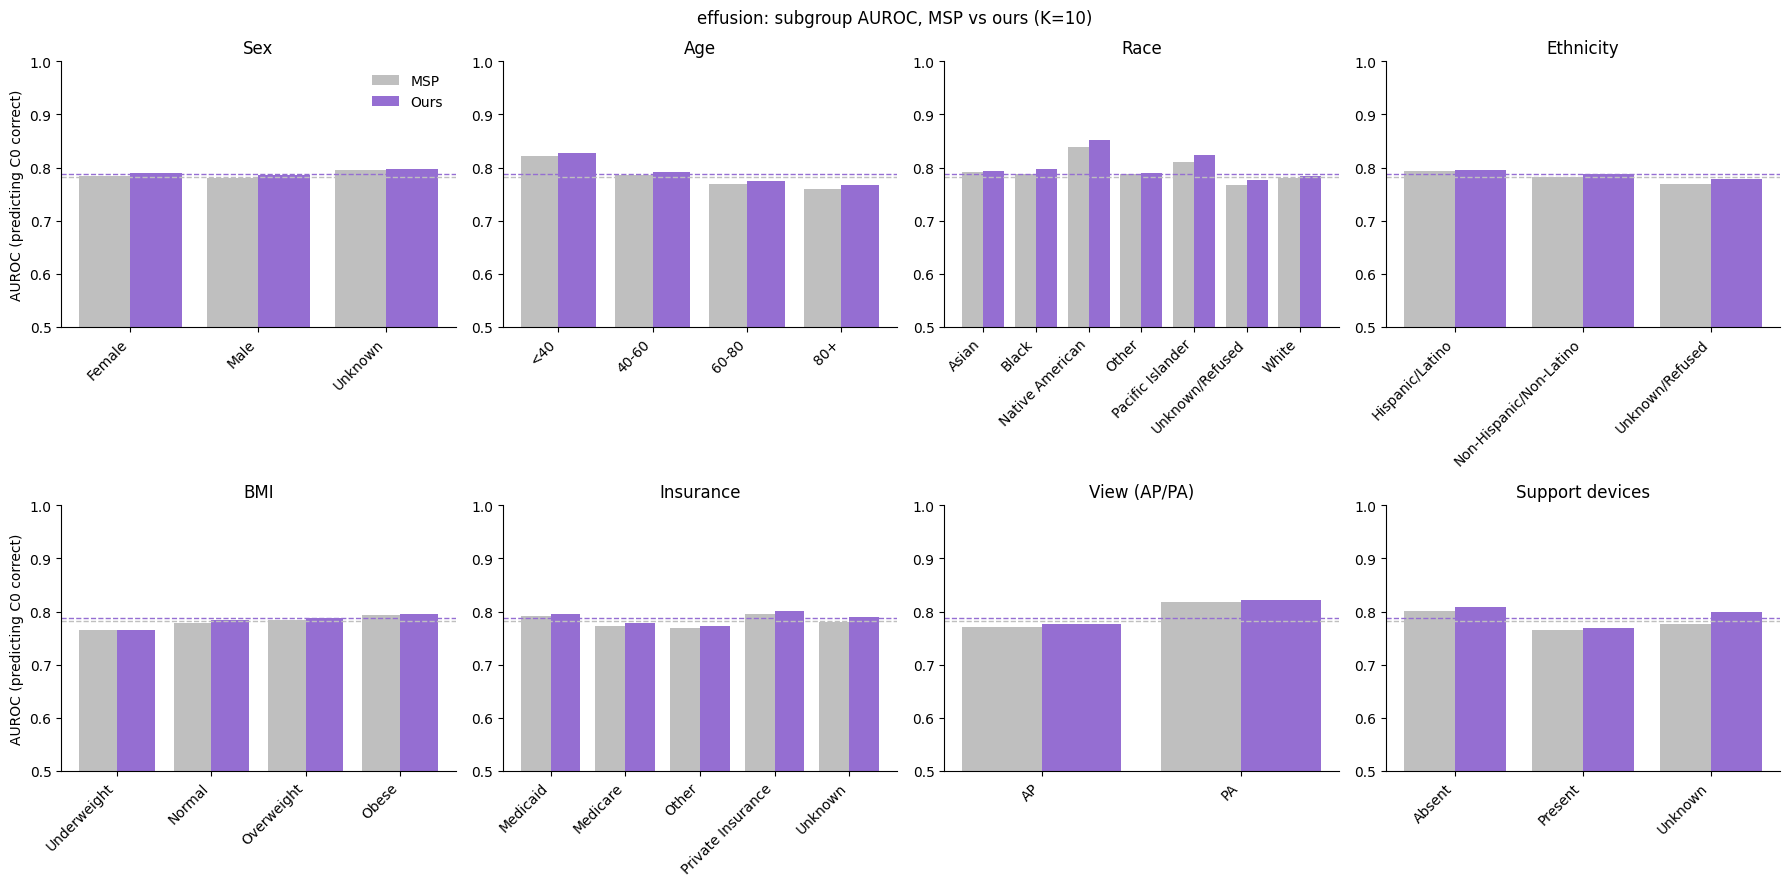

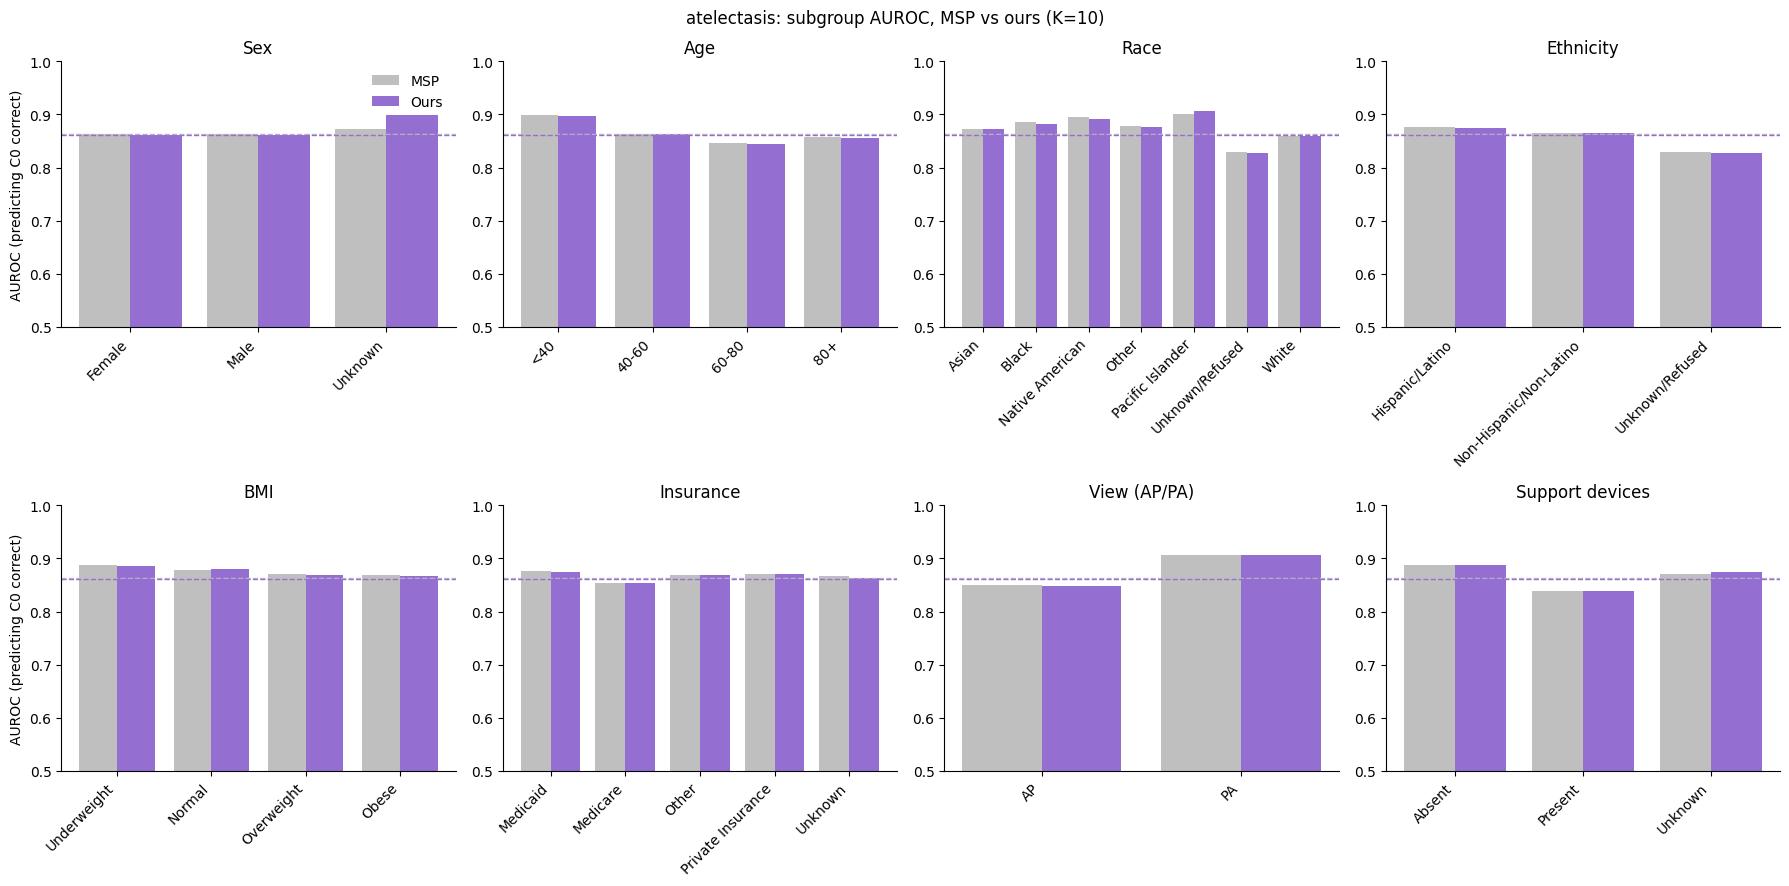

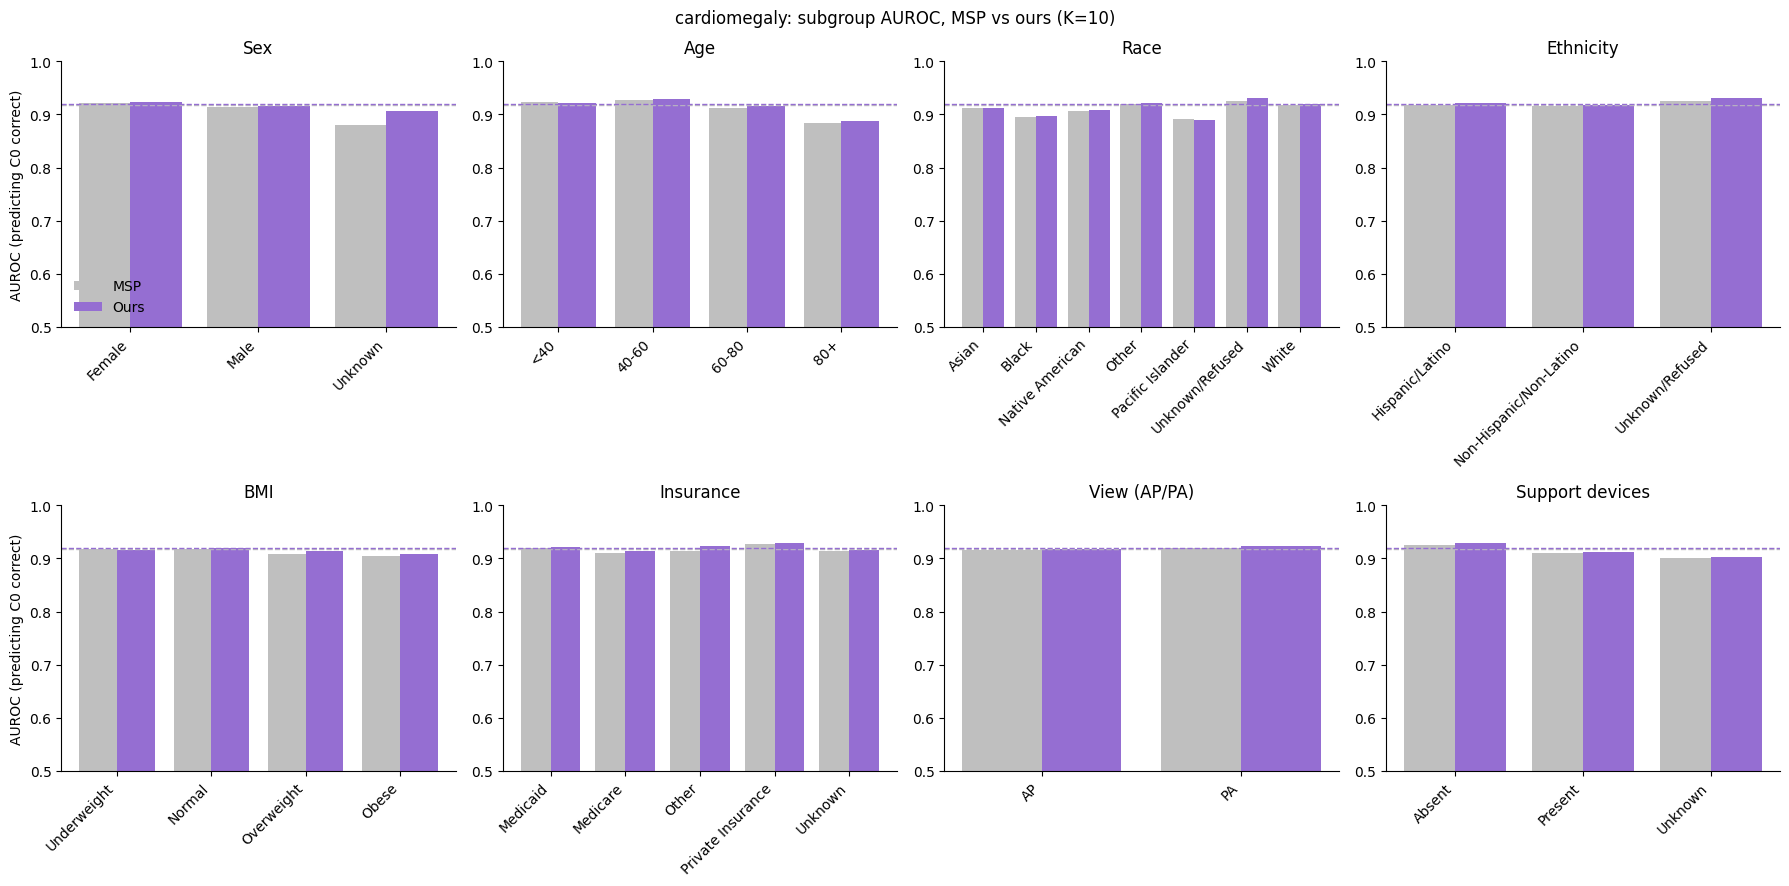

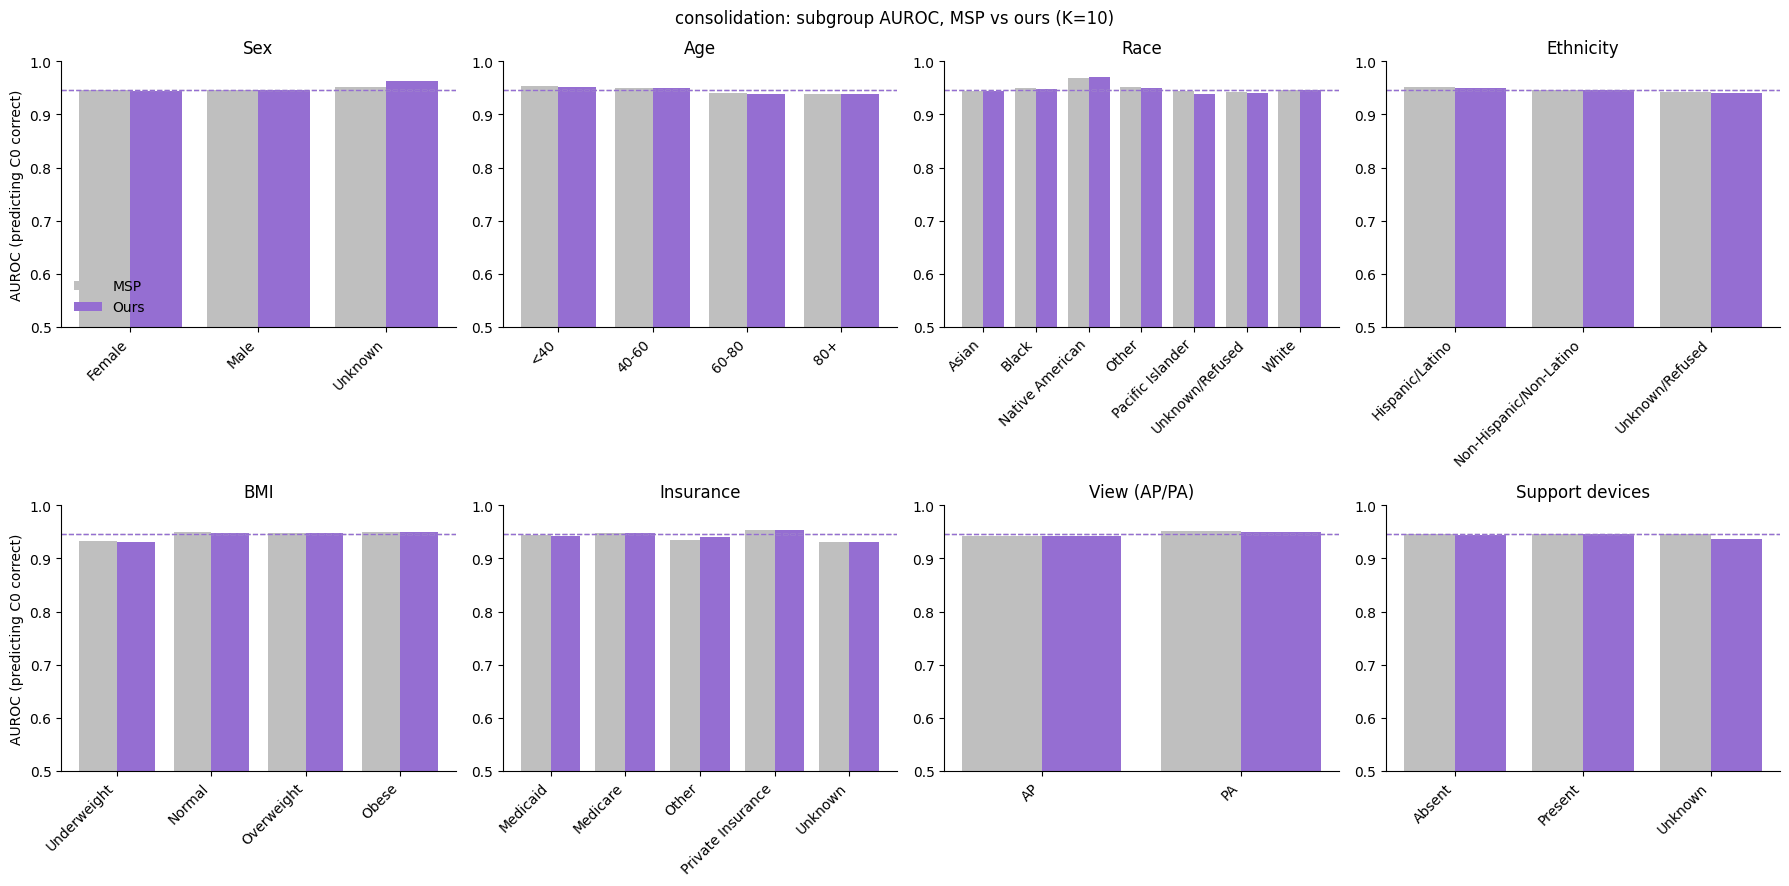

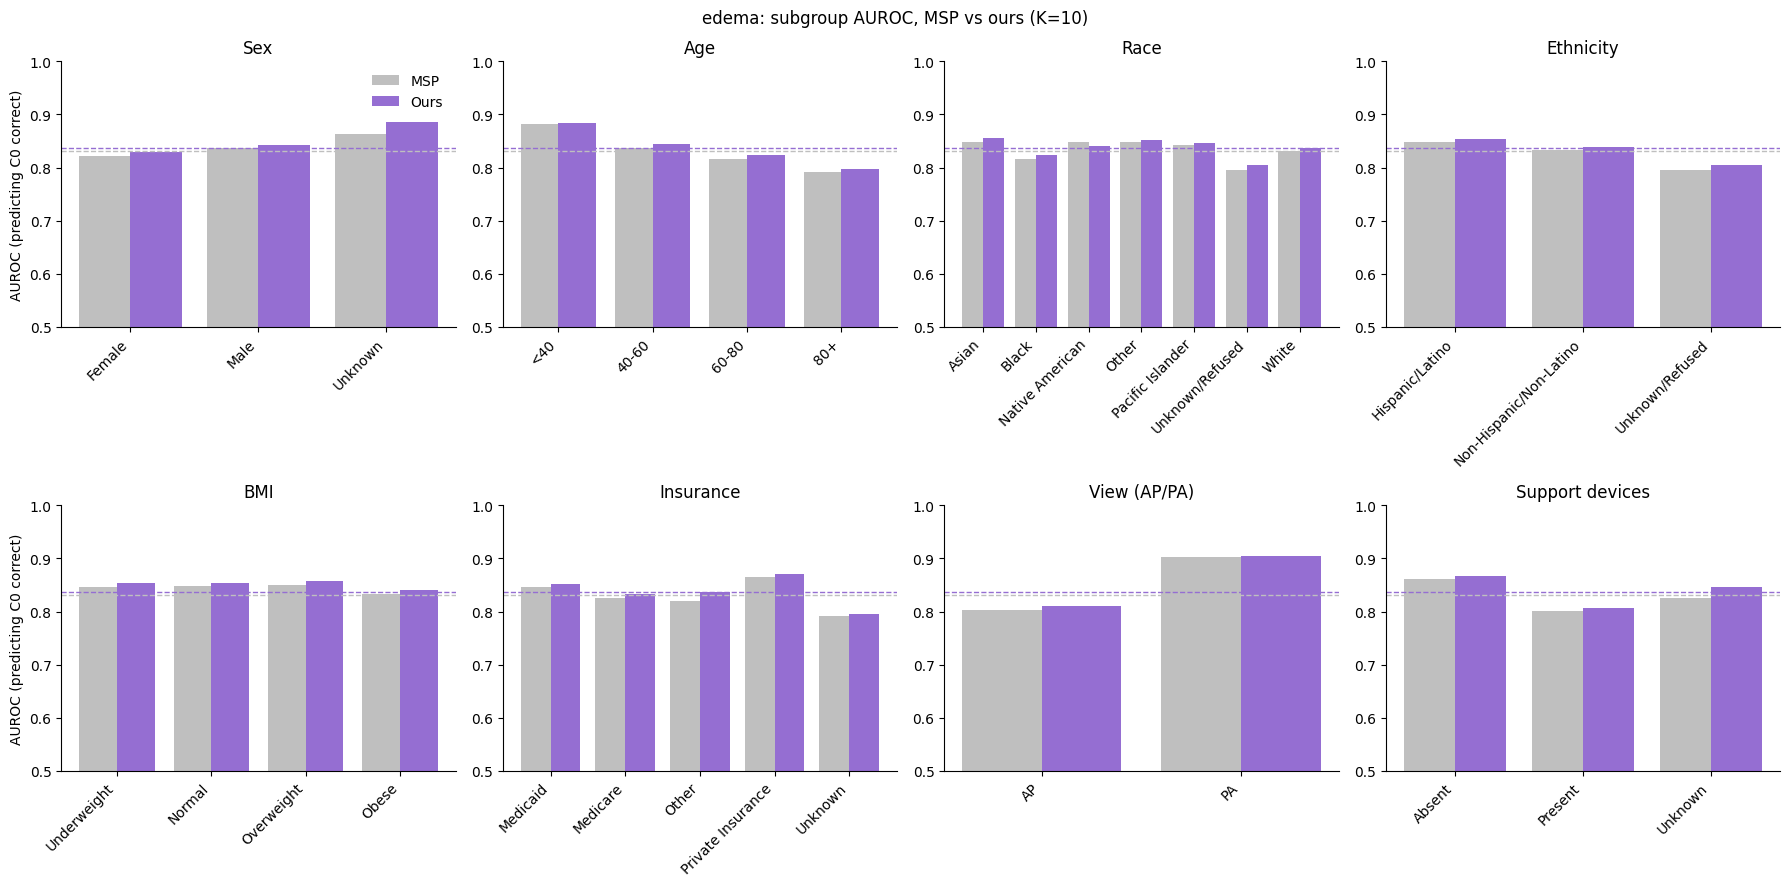

In [12]:
def plot_disease(disease):
    fig, axes = plt.subplots(2, 4, figsize=(18, 9))
    axes = axes.flatten()
    row = overall[overall["disease"] == disease].iloc[0]

    for ax, axis in zip(axes, AXES):
        table = results[(results["disease"] == disease) & (results["axis"] == axis)]
        x = np.arange(len(table))
        w = 0.4
        ax.bar(x - w/2, table["auc_msp"],  w, color=GREY, label="MSP")
        ax.bar(x + w/2, table["auc_ours"], w, color=ENS,  label="Ours")
        ax.axhline(row["auc_msp"],  color=GREY, linestyle="--", linewidth=1)
        ax.axhline(row["auc_ours"], color=ENS,  linestyle="--", linewidth=1)

        ax.set_xticks(x)
        ax.set_xticklabels(table["group"], rotation=45, ha="right")
        ax.set_title(axis)
        ax.set_ylim(0.5, 1.0)
        ax.spines[["top", "right"]].set_visible(False)

    axes[0].set_ylabel("AUROC (predicting C0 correct)")
    axes[4].set_ylabel("AUROC (predicting C0 correct)")
    axes[0].legend(frameon=False)
    fig.suptitle(f"{disease}: subgroup AUROC, MSP vs ours (K={K})")
    plt.tight_layout()
    plt.show()


for disease in DISEASES:
    plot_disease(disease)